<a href="https://colab.research.google.com/github/naveensekar2023-cell/clustering/blob/main/.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Import Libraries

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


Step 2: Load Dataset

In [19]:
df = pd.read_csv("/triple source.csv")

# Preview first rows
print("Dataset Preview:")
print(df.head())


Dataset Preview:
             Timestamp  Battery_V  Battery_I  SOC (%)  SOH (%)  Solar_V  \
0  2026-10-15 08:00:00       12.4        2.5       60       95     18.2   
1  2026-10-15 08:05:00       12.5        2.8       62       95     18.5   
2  2026-10-15 08:10:00       12.6        3.0       65       95     18.7   
3  2026-10-15 08:15:00       12.7        3.2       68       95     19.0   
4  2026-10-15 08:20:00       12.8        3.5       70       95     19.2   

   Solar_I  Engine_RPM  Alt_V  Alt_I  Motor_Speed  Motor_Torque  Throttle (%)  \
0      1.5           0    0.0    0.0          120          10.2            30   
1      1.6           0    0.0    0.0          140          11.0            35   
2      1.7           0    0.0    0.0          160          11.8            40   
3      1.9           0    0.0    0.0          180          12.5            45   
4      2.0           0    0.0    0.0          200          13.0            50   

  Brake  Ambient_Temp (°C)  Road_Grade (%)  E

Step 3: Feature Selection

In [20]:
X = df[['Battery_V','Battery_I','SOC (%)','SOH (%)','Solar_V','Solar_I',
        'Engine_RPM','Alt_V','Alt_I','Motor_Speed','Motor_Torque',
        'Throttle (%)','Brake','Ambient_Temp (°C)','Road_Grade (%)']].copy()

# Convert Brake ON/OFF to numeric safely
X.loc[:, 'Brake'] = X['Brake'].apply(lambda x: 1 if x=="ON" else 0)

# Target labels
y = df['Source_Mode'].map({'Solar':0,'Engine':1,'Combined':2,'AC Mains':3})

print("Target Labels Preview:")
print(y.head())


Target Labels Preview:
0    0
1    0
2    0
3    0
4    0
Name: Source_Mode, dtype: int64


Step 4: Preprocessing

In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)


Training set size: (26, 15)
Test set size: (7, 15)


Step 5: Build AI Model


In [22]:
model = Sequential()
model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(4, activation='softmax'))  # 4 classes

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

print("Model Summary:")
model.summary()


Model Summary:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,236 (12.64 KB)

 Trainable params: 3,236 (12.64 KB)

 Non-trainable params: 0 (0.00 B)

Step 6: Train Model

In [23]:
history = model.fit(X_train, y_train, epochs=20, batch_size=8, validation_data=(X_test, y_test))


Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.7308 - loss: 1.2498 - val_accuracy: 1.0000 - val_loss: 0.9958
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8846 - loss: 0.9887 - val_accuracy: 1.0000 - val_loss: 0.8708
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 1.0000 - loss: 0.8091 - val_accuracy: 1.0000 - val_loss: 0.7721
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 1.0000 - loss: 0.6555 - val_accuracy: 1.0000 - val_loss: 0.6853
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.5314 - val_accuracy: 1.0000 - val_loss: 0.6062
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 0.4347 - val_accuracy: 1.0000 - val_loss: 0.5334
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - loss: 0.3591 - val_accuracy: 1.0000 - val_loss: 0.4675
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 1.0000 - loss: 0.2996 - val_accuracy: 1.0000 - val_loss: 0.4094


Step 7: Evaluate Model

In [24]:
loss, acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {acc*100:.2f}%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 0.0923
Test Accuracy: 100.00%


Step 8: Visualize Training

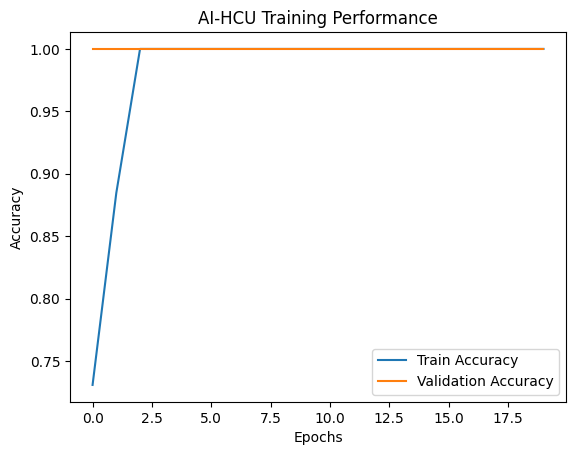

In [25]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title("AI-HCU Training Performance")
plt.show()


Step 9: Make Predictions

In [26]:
sample = X_test[0].reshape(1,-1)
prediction = model.predict(sample)
labels = ['Solar','Engine','Combined','AC Mains']
print("Predicted Source Mode:", labels[np.argmax(prediction)])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Predicted Source Mode: Engine
